# Receipt OCR with Tesseract on SROIE

**Goal:** read scanned receipts with Tesseract OCR, measure how accurate the text is, and extract four fields (company, date, address, total) with simple rules.

**Pipeline**

`receipt image → (optional) clean-up → Tesseract OCR → rule-based extraction → company / date / address / total`

**Dataset:** [SROIE 2019](https://www.kaggle.com/datasets/urbikn/sroie-datasetv2): scanned Malaysian receipts, with the correct text of every line (`box/`) and the four correct field values (`entities/`). 626 train + 347 test receipts.

**How this notebook fits in.** The heavy work (OCR on ~1,000 images) is done by the scripts; this notebook loads their results and explores them. Before running it:

```
python eval_ocr.py                    # OCR + scores, test split
python eval_ocr.py --split train      # same for train
python extract_fields.py              # field extraction, test
python extract_fields.py --split train
```

**Contents**
1. Data exploration
2. OCR quality: raw vs. clean-up vs. auto
3. Field extraction
4. Error analysis: why are answers wrong?
5. Overfitting check: test vs. train
6. Conclusions and next steps

In [1]:
%load_ext autoreload
%autoreload 2

import re, sys
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageFile

from eval_ocr import DATA, load_truth, read_ocr
from extract_fields import load_entities
from ocr import to_gray, upscale_if_small, denoise, binarize, deskew

ImageFile.LOAD_TRUNCATED_IMAGES = True   # one train image is slightly corrupt
pd.set_option("display.max_colwidth", 90)
plt.rcParams["figure.dpi"] = 110

SPLITS = ["train", "test"]
FIELDS = ["company", "date", "address", "total"]
RESULTS = Path("results")
PSM = 4            # Tesseract page mode used in the runs
MIN_WORDS = 20     # auto mode: below this many raw words, use the clean-up result


def squash(s):
    """Uppercase and drop everything except letters/digits, for loose 'is this text in there?' checks."""
    return re.sub(r"[^A-Z0-9]", "", str(s).upper())


print(sys.executable)   # should point inside tesseract-ocr\ (the venv)

Matplotlib is building the font cache; this may take a moment.


d:\sroie-ocr-tesseract\tesseract-ocr\Scripts\python.exe


## 1. Data exploration

### 1.1 Files per split
Every receipt should have one image, one `box` file (text lines + coordinates) and one `entities` file (the four fields).

In [2]:
counts = pd.DataFrame({
    split: {folder: len(list((DATA / split / folder).glob("*"))) for folder in ["img", "box", "entities"]}
    for split in SPLITS
})
counts

,train,test
img,626,347
box,626,347
entities,626,347


### 1.2 One table with everything per receipt
For each receipt: image size, brightness/contrast, the ground-truth text and its length, and the four fields.

- `ink` = how dark the darkest 2% of pixels are (0 = black ink, higher = paler / faded ink)
- `contrast` = difference between the lightest and darkest pixels

*Takes about a minute: it opens all ~970 images.*

In [3]:
def image_stats(path):
    with Image.open(path) as im:
        w, h = im.size
        im.draft("L", (w // 2, h // 2))          # fast JPEG decode at half size
        g = np.asarray(im.convert("L"), dtype=np.float32)
    p2, p98 = np.percentile(g, [2, 98])
    return {"width": w, "height": h, "brightness": g.mean(), "ink": p2, "contrast": p98 - p2}


rows = []
for split in SPLITS:
    for img_path in sorted((DATA / split / "img").glob("*.jpg")):
        rid = img_path.stem
        text = load_truth(DATA / split / "box" / f"{rid}.txt")
        ent = load_entities(DATA / split / "entities" / f"{rid}.txt") or {}
        rows.append({
            "split": split, "id": rid,
            **image_stats(img_path),
            "kb": img_path.stat().st_size / 1024,
            "text": text,
            "lines": len(text.splitlines()), "words": len(text.split()), "chars": len(text),
            **{f: (ent.get(f) or "").strip() for f in FIELDS},
        })

df = pd.DataFrame(rows)
print(df.shape)
df.drop(columns="text").head()

(973, 16)


,split,id,width,height,brightness,ink,contrast,kb,lines,words,chars,company,date,address,total
0,train,X00016469612,463,1013,244.784592,116.0,139.0,95.820312,44,85,485,BOOK TA .K (TAMAN DAYA) SDN BHD,25/12/2018,"NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 81100 JOHOR BAHRU, JOHOR.",9.00
1,train,X00016469619,439,1004,248.170334,184.0,71.0,83.792969,48,102,684,INDAH GIFT & HOME DECO,19/10/2018,"27, JALAN DEDAP 13, TAMAN JOHOR JAYA, 81100 JOHOR BAHRU, JOHOR.",60.30
2,train,X00016469620,459,949,241.205276,114.0,141.0,122.041992,54,123,723,MR D.I.Y. (JOHOR) SDN BHD,12-01-19,"LOT 1851-A & 1851-B, JALAN KPB 6, KAWASAN PERINDUSTRIAN BALAKONG, 43300 SERI KEMBANGAN...",33.90
3,train,X00016469622,461,933,245.867126,135.0,120.0,91.370117,60,105,584,YONGFATT ENTERPRISE,25/12/2018,NO 122.124. JALAN DEDAP 13 81100 JOHOR BAHRU,80.90
4,train,X00016469623,463,1026,245.984238,181.0,74.0,100.424805,61,144,797,MR D.I.Y. (M) SDN BHD,18-11-18,"LOT 1851-A & 1851-B, JALAN KPB 6, KAWASAN PERINDUSTRIAN BALAKONG, 43300 SERI KEMBANGAN...",30.90


### 1.3 Image sizes
Tesseract works best when letters are about 30 px tall, so resolution matters.

In [4]:
df.groupby("split")[["width", "height", "kb"]].describe().T.round(0)

split           test   train
width  count   347.0   626.0
       mean   1421.0  1326.0
       std    1499.0  1414.0
       min     435.0   436.0
       25%     703.0   623.0
       50%     880.0   812.0
       75%     935.0   935.0
       max    4961.0  4961.0
height count   347.0   626.0
       mean   2483.0  2356.0
       std    1948.0  1841.0
       min     776.0   605.0
       25%    1412.0  1396.0
       50%    1728.0  1682.0
       75%    2212.0  2141.0
       max    7016.0  7016.0
kb     count   347.0   626.0
       mean    579.0   554.0
       std     625.0   573.0
       min     104.0    58.0
       25%     264.0   246.0
       50%     344.0   347.0
       75%     551.0   551.0
       max    4153.0  3540.0

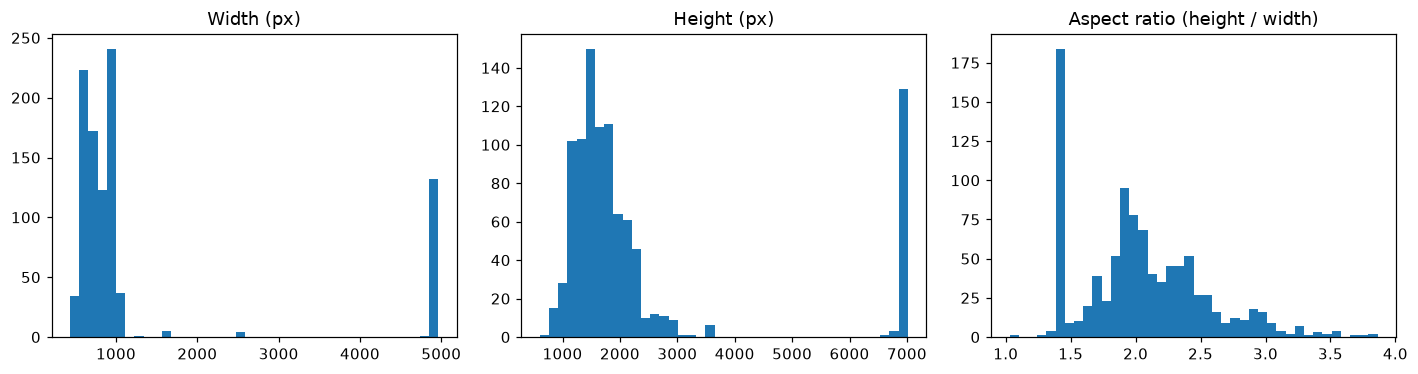

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(df.width, bins=40);              axes[0].set_title("Width (px)")
axes[1].hist(df.height, bins=40);             axes[1].set_title("Height (px)")
axes[2].hist(df.height / df.width, bins=40);  axes[2].set_title("Aspect ratio (height / width)")
plt.tight_layout(); plt.show()

### 1.4 What the receipts look like

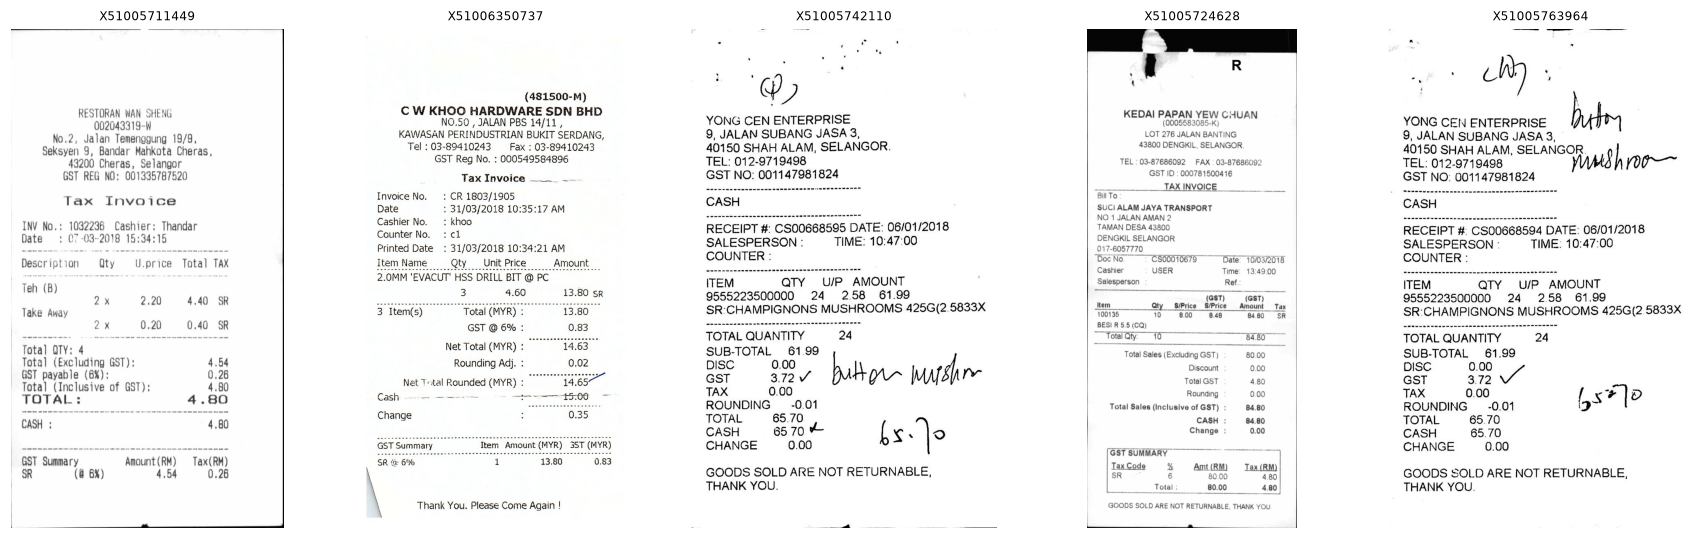

In [6]:
def show_receipts(rows, extra=None, height=5):
    """Show receipts side by side. `extra` = a column name to print under the id."""
    fig, axes = plt.subplots(1, len(rows), figsize=(3.2 * len(rows), height))
    for ax, (_, r) in zip(np.atleast_1d(axes), rows.iterrows()):
        ax.imshow(Image.open(DATA / r["split"] / "img" / f"{r['id']}.jpg").convert("RGB"))
        title = r["id"] if extra is None else f"{r['id']}\n{extra} = {r[extra]:.0f}"
        ax.set_title(title, fontsize=8)
        ax.axis("off")
    plt.tight_layout(); plt.show()


show_receipts(df[df.split == "test"].sample(5, random_state=1))

### 1.5 What the annotations look like
Each line of a `box` file is `x1,y1,x2,y2,x3,y3,x4,y4,TEXT`: the four corners of a box, then the text inside it.

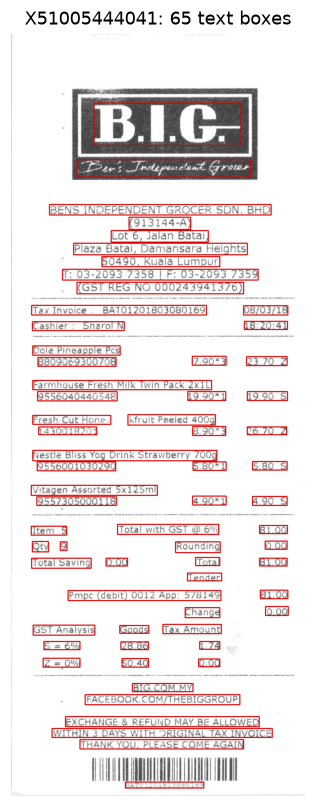

First box lines:
223,186,618,186,618,300,223,300,B.I.G.
177,338,643,338,643,385,177,385,BEN'S INDEPENDENT GROCER
103,459,699,459,699,487,103,487,BENS INDEPENDENT GROCER SDN. BHD
317,493,483,493,483,526,317,526,(913144-A)
269,529,530,529,530,560,269,560,LOT 6, JALAN BATAI,
168,563,635,563,635,594,168,594,PLAZA BATAI, DAMANSARA HEIGHTS

Entities:
{
    "company": "BENS INDEPENDENT GROCER SDN. BHD",
    "date": "08/03/18",
    "address": "LOT 6, JALAN BATAI, PLAZA BATAI, DAMANSARA HEIGHTS 50490, KUALA LUMPUR",
    "total": "81.00"
}


In [7]:
def load_boxes(path):
    boxes = []
    for row in path.read_text(encoding="utf-8-sig", errors="replace").splitlines():
        parts = row.split(",", 8)
        if len(parts) != 9:
            continue
        try:
            pts = np.array(list(map(int, parts[:8]))).reshape(4, 2)
        except ValueError:
            continue
        boxes.append((pts, parts[8]))
    return boxes


rid = "X51005444041"
img = cv2.cvtColor(cv2.imread(str(DATA / "test" / "img" / f"{rid}.jpg")), cv2.COLOR_BGR2RGB)
boxes = load_boxes(DATA / "test" / "box" / f"{rid}.txt")
for pts, _ in boxes:
    cv2.polylines(img, [pts.reshape(-1, 1, 2)], True, (220, 0, 0), 2)

plt.figure(figsize=(5, 9)); plt.imshow(img); plt.axis("off")
plt.title(f"{rid}: {len(boxes)} text boxes"); plt.show()

print("First box lines:")
print("\n".join((DATA / "test" / "box" / f"{rid}.txt").read_text(encoding="utf-8", errors="replace").splitlines()[:6]))
print("\nEntities:")
print((DATA / "test" / "entities" / f"{rid}.txt").read_text(encoding="utf-8", errors="replace"))

### 1.6 How much text is on a receipt?

split          test   train
lines count   347.0   626.0
      mean     54.0    54.0
      std      17.0    18.0
      min      23.0    18.0
      25%      42.0    42.0
      50%      51.0    50.0
      75%      64.0    63.0
      max     121.0   153.0
words count   347.0   626.0
      mean    114.0   116.0
      std      33.0    33.0
      min      54.0    27.0
      25%      90.0    91.0
      50%     108.0   109.0
      75%     130.0   132.0
      max     211.0   240.0
chars count   347.0   626.0
      mean    662.0   671.0
      std     180.0   181.0
      min     289.0   187.0
      25%     532.0   540.0
      50%     621.0   636.0
      75%     761.0   770.0
      max    1307.0  1368.0

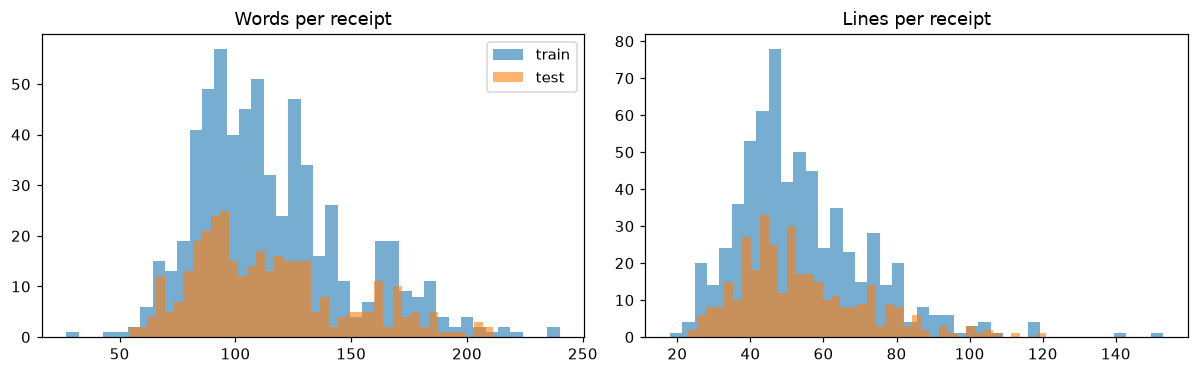

In [8]:
display(df.groupby("split")[["lines", "words", "chars"]].describe().T.round(0))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for split in SPLITS:
    axes[0].hist(df[df.split == split].words, bins=40, alpha=0.6, label=split)
    axes[1].hist(df[df.split == split].lines, bins=40, alpha=0.6, label=split)
axes[0].set_title("Words per receipt"); axes[1].set_title("Lines per receipt")
axes[0].legend(); plt.tight_layout(); plt.show()

### 1.7 Image quality: faded receipts
Thermal-paper receipts fade over time. A high `ink` value means even the darkest pixels are fairly light, so the text is pale. These receipts should be the hardest for OCR. Section 2 checks this.

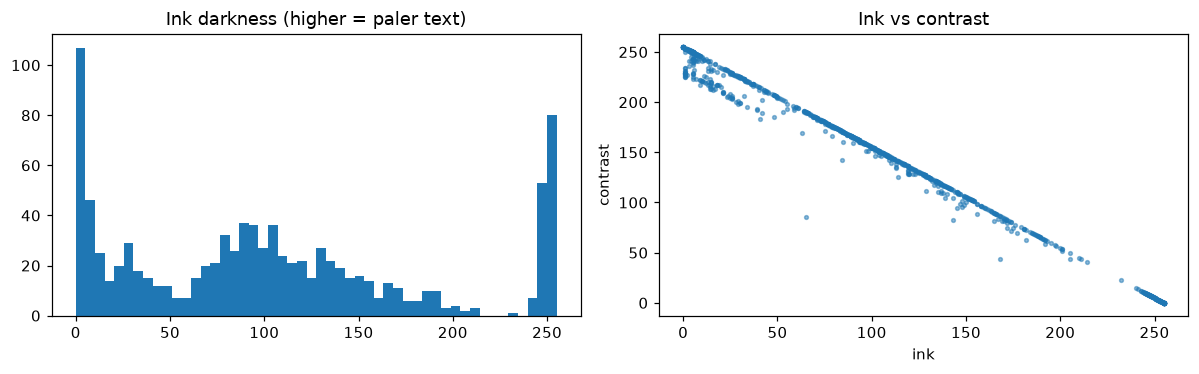

Palest receipts:


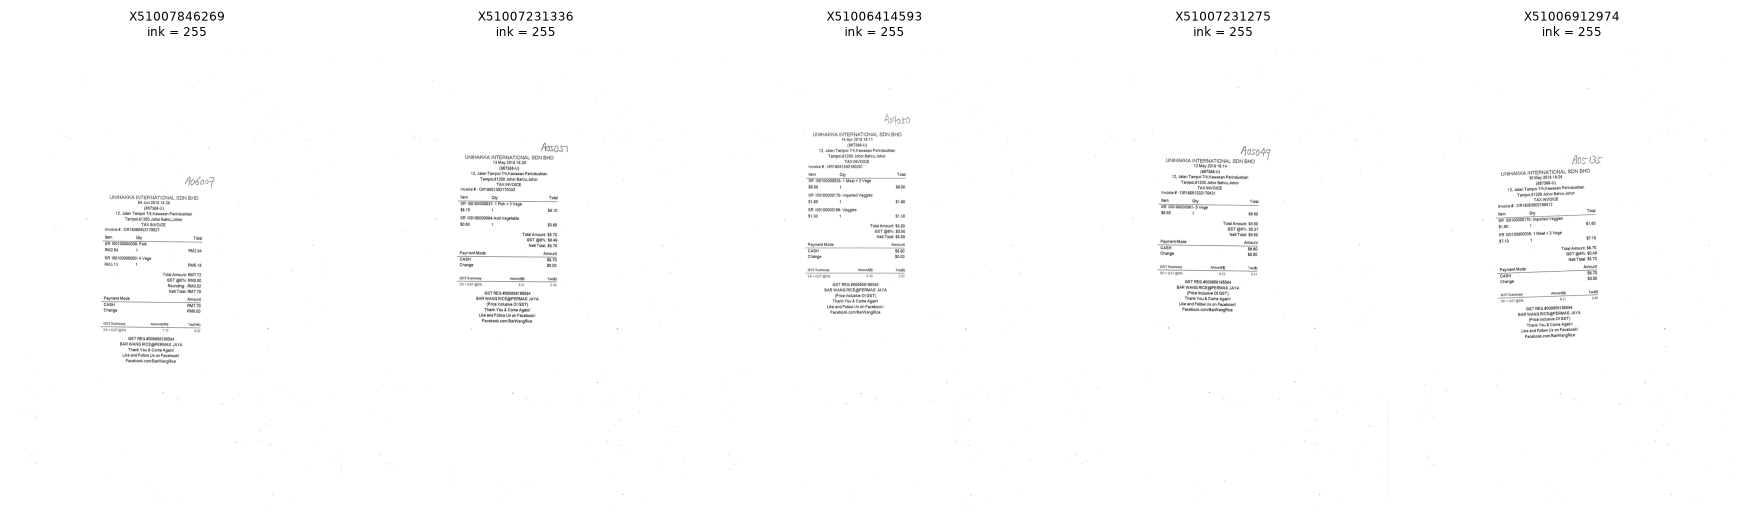

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(df.ink, bins=50);   axes[0].set_title("Ink darkness (higher = paler text)")
axes[1].scatter(df.ink, df.contrast, s=6, alpha=0.5)
axes[1].set_xlabel("ink"); axes[1].set_ylabel("contrast"); axes[1].set_title("Ink vs contrast")
plt.tight_layout(); plt.show()

print("Palest receipts:")
show_receipts(df.sort_values("ink", ascending=False).head(5), extra="ink")

### 1.8 Characters in the ground truth
Which kinds of characters does OCR need to get right?

In [10]:
chars = Counter(c for t in df.text for c in t if not c.isspace())

def kind(c):
    if c.isupper(): return "uppercase"
    if c.islower(): return "lowercase"
    if c.isdigit(): return "digit"
    return "punctuation / other"

kinds = Counter()
for c, n in chars.items():
    kinds[kind(c)] += n
display((pd.Series(kinds) / sum(kinds.values())).sort_values(ascending=False).round(3).to_frame("share"))

punct = Counter({c: n for c, n in chars.items() if kind(c) == "punctuation / other"})
print("Most common punctuation:", " ".join(c for c, _ in punct.most_common(15)))
print("Non-ASCII characters:", sorted(c for c in chars if ord(c) > 127))

,share
uppercase,0.641
digit,0.253
punctuation / other,0.106
lowercase,0.000


Most common punctuation: . : - ( ) , / % * @ & $ # ' !
Non-ASCII characters: ['·', '�']


### 1.9 The four fields

**Missing values per field**

In [11]:
(df[FIELDS] == "").groupby(df.split).sum()

,company,date,address,total
split,,,,
test,0,0,0,0
train,0,0,1,1


**Date formats.** Digits are shown as `9` and letters as `A`, so each row shows the *shape* of a date.

In [12]:
shape = df.date.str.upper().str.replace(r"\d", "9", regex=True).str.replace(r"[A-Z]", "A", regex=True)
shape.value_counts().head(12).to_frame("receipts")

,receipts
date,
99/99/9999,517
99-99-99,113
99-99-9999,108
99/99/99,95
99 AAA 9999,81
99/AAA/9999,10
9/9/9999,9
99 AAA 99,9
99-AAA-9999,9


**Totals.** What range of amounts, and how many are rounded to 5 sen (Malaysian cash rounding)?

,total (RM)
count,972.00
mean,66.93
std,269.30
min,0.90
25%,8.70
50%,26.95
75%,63.41
max,7838.80


Multiples of 0.05: 89.3%


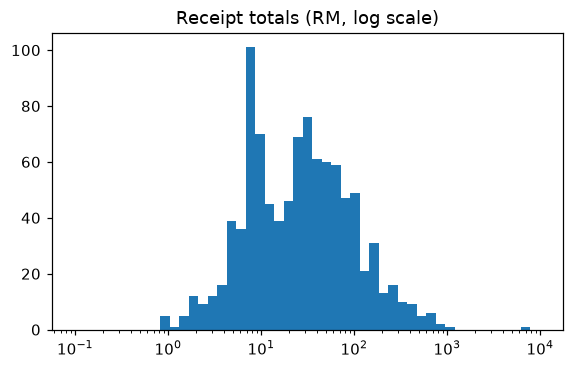

In [13]:
totals = pd.to_numeric(df.total.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
display(totals.describe().round(2).to_frame("total (RM)"))
valid = totals.dropna()
print(f"Multiples of 0.05: {np.isclose(np.round(valid * 20) / 20, valid).mean():.1%}")

plt.figure(figsize=(6, 3.5))
plt.hist(valid[valid > 0], bins=np.logspace(-1, 4, 50)); plt.xscale("log")
plt.title("Receipt totals (RM, log scale)"); plt.show()

**Companies.** The same shops appear many times, and some appear in both train and test.

In [14]:
display(df.company.value_counts().head(12).to_frame("receipts"))

train_companies = set(df[df.split == "train"].company)
test_df = df[df.split == "test"]
print(f"Test receipts whose company also appears in train: {test_df.company.isin(train_companies).mean():.1%}")

,receipts
company,
GARDENIA BAKERIES (KL) SDN BHD,76
UNIHAKKA INTERNATIONAL SDN BHD,69
SANYU STATIONERY SHOP,49
99 SPEED MART S/B,44
MR. D.I.Y. (M) SDN BHD,41
RESTORAN WAN SHENG,40
SYARIKAT PERNIAGAAN GIN KEE,33
AEON CO. (M) BHD,23
KEDAI PAPAN YEW CHUAN,19


Test receipts whose company also appears in train: 72.6%


### 1.10 Are the answers consistent with the receipt text?
If an `entities` answer can't be found in the receipt's own `box` text (ignoring spaces and punctuation), then even perfect OCR couldn't match it exactly. This measures **label noise**.

In [15]:
for f in FIELDS:
    df[f"{f}_in_text"] = [float(squash(v) in squash(t)) if v else np.nan for v, t in zip(df[f], df.text)]

display(df.groupby("split")[[f"{f}_in_text" for f in FIELDS]].mean().round(3))

print("Examples where the address answer is NOT in the receipt text:")
df[df.address_in_text == 0][["split", "id", "address"]].head(5)

,company_in_text,date_in_text,address_in_text,total_in_text
split,,,,
test,0.983,0.988,0.957,1.0
train,0.979,0.995,0.944,1.0


Examples where the address answer is NOT in the receipt text:


,split,id,address
13,train,X51005268400,NO.2-1-1 JALAN SEITA PRIMA Q U 13/Q SEITA ALAM 40170 SHAN ALAM SELANGOR
24,train,X51005361898,"NO.53, JALAN BESAR, 45600 BATANG BEJUNTAL SELANGOR DARUL EHSAN"
31,train,X51005433494,"3RD FLR, AEON TAMAN MALURI SD JLN JEJAKA, TAMAN MALURI CHERAS, 55100 KUALA LUMPUR"
39,train,X51005441398,"AVTIVO PLAZA,LOT B-F-11, BLOCK B NO1.JALAN PJU 9/1,D'SARA AVEVUE BANDAR SRI D'SARA, 52..."
44,train,X51005442327,"12, JALAN TAMPOI 7/4,KAWASAN PARINDUSTRIAN TAMPOI,81200 JOHOR BAHRU,JOHOR"


### 1.11 Key findings from data exploration

- **Complete splits.** 626 train and 347 test receipts, each with an image, a `box` file and an `entities` file. Only one train receipt has empty fields (address and total).
- **Image sizes vary a lot.** Widths range from 435 to 4,961 px (median 812 px train, 880 px test) and file sizes from 58 KB to 4 MB, so low- and high-resolution scans are mixed.
- **Train and test look alike.** A typical receipt has about 50 lines, 108 words and 630 characters in both splits.
- **The ground truth is uppercase only.** 64% of characters are uppercase letters, 25% digits, 11% punctuation, and essentially none lowercase, which is why scoring compares text in uppercase. A few `box` files contain a broken character (`�`), a sign of encoding problems in the annotations.
- **Ink darkness varies widely.** The median `ink` is 95, but on the palest receipts even the darkest pixels are around 200 (light grey): faded thermal print.
- **Dates come in 12+ formats.** `dd/mm/yyyy` is the most common (517 of 973), followed by `dd-mm-yy` (113), `dd-mm-yyyy` (108), `dd/mm/yy` (95) and `dd MON yyyy` (81). A few use `yyyy-mm-dd` or 8 digits with no separator, which the date rules don't cover.
- **Totals are mostly rounded to 5 sen.** Median RM 26.95 (range RM 0.90–7,838.80), and 89% are multiples of 0.05.
- **A few shops dominate.** The 12 most common companies account for 444 receipts (46%), and 73% of test receipts come from a shop that also appears in train.
- **The answer key has some noise.** The answer appears in the receipt's own text for 100% of totals, about 99% of dates, 98% of companies and 95% of addresses. The address misses are spelling differences from the receipt (e.g. `SHAN ALAM`, `BEJUNTAL`, `AVTIVO`, `PARINDUSTRIAN`), so about 5% of addresses can never be matched exactly.

## 2. OCR quality: raw vs. clean-up vs. auto

Three ways of feeding a receipt to Tesseract (`--psm 4` = single column of text):

| Mode | What it does |
|---|---|
| **raw** | grayscale only |
| **clean** | `ocr.py` clean-up: enlarge small images, remove grain, adaptive black-and-white, straighten |
| **auto** | use raw, but if raw finds fewer than 20 words, use clean instead |

Scores compare the OCR text with the `box` text:
- **CER / WER**: character / word error rate (lower is better). Both also count reading-order differences as errors.
- **word P / R / F1**: bag-of-words precision, recall, F1 (higher is better). Order doesn't matter, so this is the fairest single number.

### 2.1 Overall scores

In [16]:
ocr = pd.concat([pd.read_csv(RESULTS / s / f"psm{PSM}" / "scores.csv").assign(split=s) for s in SPLITS])
MODES = ["raw", "clean", "auto"]


def corpus_scores(g):
    """Same weighting as eval_ocr.py: long receipts count more."""
    p = g.matched_words.sum() / g.hyp_words.sum()
    r = g.matched_words.sum() / g.ref_words.sum()
    return pd.Series({
        "CER": (g.cer * g.ref_chars).sum() / g.ref_chars.sum(),
        "WER": (g.wer * g.ref_words).sum() / g.ref_words.sum(),
        "word P": p, "word R": r, "word F1": 2 * p * r / (p + r),
    })


cols = ["ref_chars", "ref_words", "hyp_words", "matched_words", "cer", "wer"]
ocr_summary = ocr.groupby(["split", "mode"])[cols].apply(corpus_scores)
ocr_summary = ocr_summary.reindex(pd.MultiIndex.from_product([["test", "train"], MODES], names=["split", "mode"]))
(ocr_summary * 100).round(1)

CER   WER  word P  word R  word F1
split mode                                      
test  raw    26.2  47.2    70.7    70.4     70.5
      clean  25.3  50.8    65.3    69.6     67.4
      auto   24.4  46.7    69.3    71.9     70.6
train raw    25.1  46.8    69.9    70.4     70.1
      clean  24.3  49.8    65.6    69.0     67.2
      auto   24.1  46.6    69.2    71.0     70.1

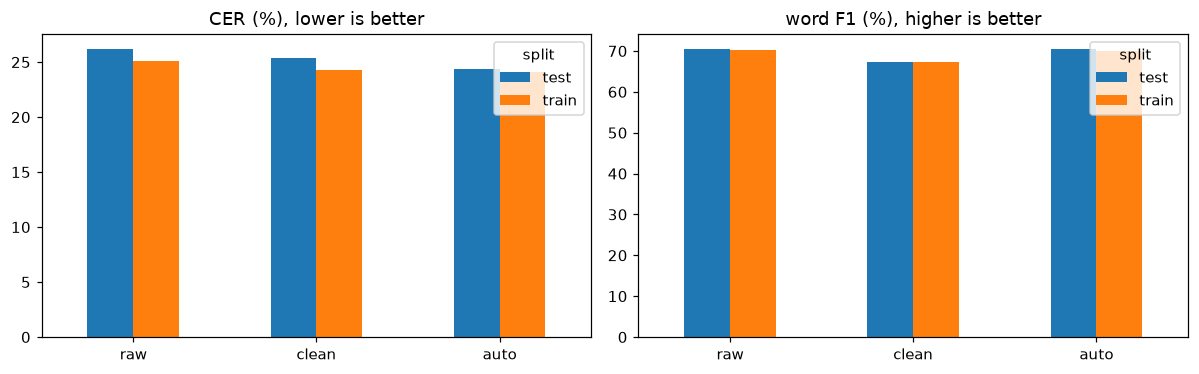

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, metric, note in zip(axes, ["CER", "word F1"], ["lower is better", "higher is better"]):
    (ocr_summary[metric].unstack("split")[["test", "train"]].reindex(MODES) * 100).plot.bar(ax=ax, rot=0)
    ax.set_title(f"{metric} (%), {note}"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Receipts where OCR returned no text at all**

In [18]:
ocr[ocr.hyp_words == 0].groupby(["split", "mode"]).size().unstack(fill_value=0)

mode,raw
split,
test,11
train,6


### 2.2 Per receipt: when does clean-up help?
Each dot is one receipt. **Below the diagonal = clean-up lowered the error.** Colour = `ink` from section 1.7 (yellow = palest).

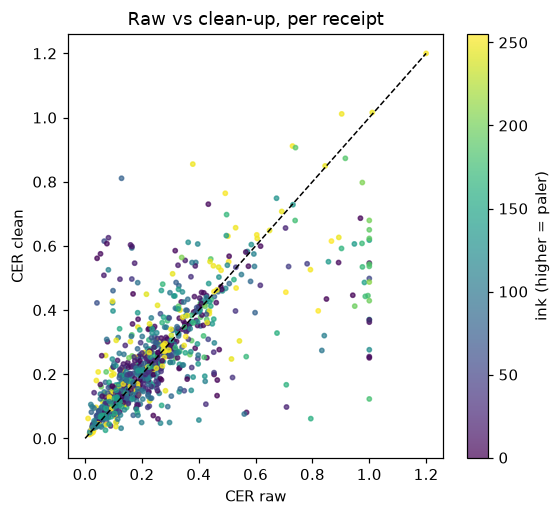

clean-up better by > 2 points: 29.6% of receipts
clean-up worse  by > 2 points: 34.5% of receipts


In [19]:
wide = ocr.pivot_table(index=["split", "id"], columns="mode", values="cer").reset_index()
wide = wide.merge(df[["split", "id", "ink", "contrast"]], on=["split", "id"])
wide["gain"] = wide["raw"] - wide["clean"]          # > 0 means clean-up helped

fig, ax = plt.subplots(figsize=(5.5, 5))
sc = ax.scatter(wide.raw.clip(upper=1.2), wide.clean.clip(upper=1.2), c=wide.ink, cmap="viridis", s=8, alpha=0.7)
ax.plot([0, 1.2], [0, 1.2], "k--", lw=1)
ax.set_xlabel("CER raw"); ax.set_ylabel("CER clean"); ax.set_title("Raw vs clean-up, per receipt")
plt.colorbar(sc, label="ink (higher = paler)"); plt.show()

print(f"clean-up better by > 2 points: {(wide.gain > 0.02).mean():.1%} of receipts")
print(f"clean-up worse  by > 2 points: {(wide.gain < -0.02).mean():.1%} of receipts")

If the "faded receipts" idea is right, clean-up should help most in the **palest** group. Receipts are split into 5 equal groups by `ink`:

,receipts,raw_CER,clean_CER,gain
ink_group,,,,
1 darkest ink,195,0.271,0.270,0.000
2,194,0.203,0.204,-0.000
3,195,0.197,0.196,0.002
4,194,0.261,0.248,0.014
5 palest ink,195,0.341,0.317,0.023


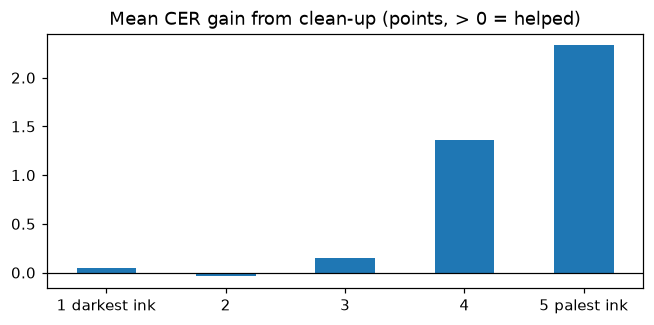

In [20]:
wide["ink_group"] = pd.qcut(wide.ink.rank(method="first"), 5,
                            labels=["1 darkest ink", "2", "3", "4", "5 palest ink"])
by_ink = wide.groupby("ink_group", observed=True).agg(
    receipts=("id", "size"), raw_CER=("raw", "mean"), clean_CER=("clean", "mean"), gain=("gain", "mean"))
display(by_ink.round(3))

ax = (by_ink.gain * 100).plot.bar(rot=0, figsize=(7, 3), title="Mean CER gain from clean-up (points, > 0 = helped)")
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel(""); plt.show()

### 2.3 A faded receipt, step by step
These are the receipts where raw OCR returned nothing:

In [21]:
raw_empty = ocr[(ocr["mode"] == "raw") & (ocr.hyp_words == 0)][["split", "id"]]
display(raw_empty.merge(df[["split", "id", "ink", "contrast"]], on=["split", "id"]).round(1))
print(f"Median ink over all receipts: {df.ink.median():.1f}")

,split,id,ink,contrast
0,train,X51006619550,8.0,243.0
1,train,X51006619862,192.0,59.0
2,train,X51006620187,198.0,57.0
3,train,X51006733494,210.0,45.0
4,train,X51006828217,14.0,238.0
5,train,X51008142034,123.0,128.0
6,test,X51005663309,0.0,255.0
7,test,X51005719863,5.0,237.0
8,test,X51005749904,179.0,76.0
9,test,X51006388081,144.0,110.0


Median ink over all receipts: 95.0


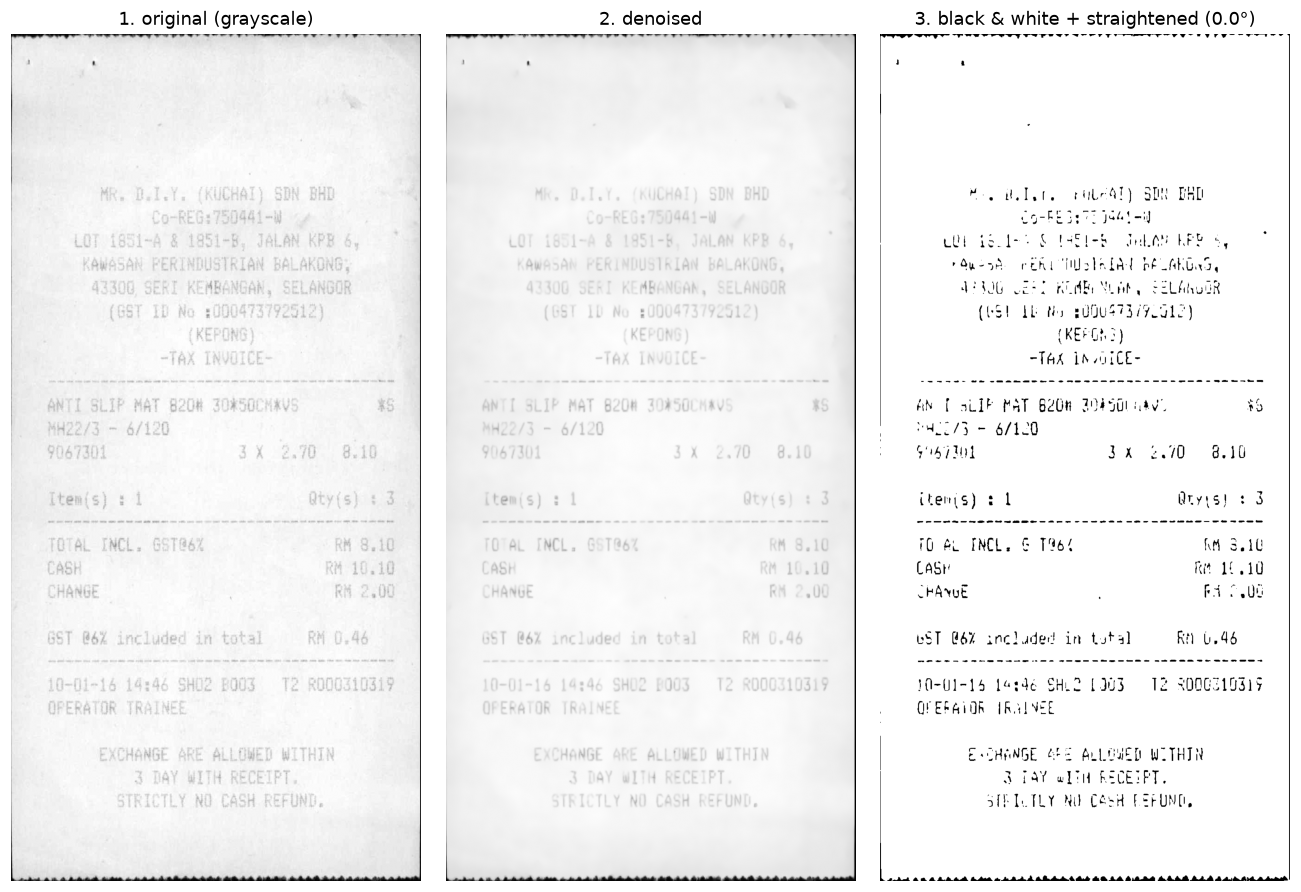

In [22]:
rid = "X51006619700"
img = cv2.imread(str(DATA / "test" / "img" / f"{rid}.jpg"))
gray = to_gray(img)
den = denoise(upscale_if_small(gray))
bw = binarize(den)
final, angle = deskew(bw)

fig, axes = plt.subplots(1, 3, figsize=(12, 8))
titles = ["1. original (grayscale)", "2. denoised", f"3. black & white + straightened ({angle:.1f}°)"]
for ax, im, title in zip(axes, [gray, den, final], titles):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

In [23]:
run_dir = RESULTS / "test" / f"psm{PSM}"
for mode in ["raw", "clean"]:
    text = (run_dir / mode / f"{rid}.txt").read_text(encoding="utf-8").strip()
    print(f"===== {mode}: {len(text.split())} words")
    print("\n".join(text.splitlines()[:12]) or "(nothing)")
    print()

===== raw: 0 words
(nothing)

===== clean: 122 words
eel it tein Tie ri in i i ee ene

Mosaic. rile) oth TaD
workoas
(GS! Lb te sugustaiyoae)
(KEF GH?)

Leb Golde. & sb leb  tebay RPE Ss,

rOy-oA een sta dad pe AKAs,

VQG asl KUAB Sone SStAn oR



**Takeaway**

- Raw OCR returned **no text** for 17 receipts (11 test, 6 train). 11 of them are paler than the median receipt (`ink` > 95), so fading explains most cases, but not all. The other 6 have dark ink (`ink` ≤ 54) and fail for another reason, possibly dark borders or backgrounds around the receipt (not yet checked).
- Clean-up produces text for all 17, but the quality varies. For `X51006619700` above, the output is mostly garbage (122 words, only about 11 correct). For `X51005749904`, another faded receipt, the result is good (CER about 12%).
- Over all receipts, clean-up helps about as often as it hurts (better on 29.6%, worse on 34.5%). Its benefit is concentrated in the palest receipts: the mean CER gain is about 0 for the three darkest `ink` groups, +1.4 points for group 4 and +2.3 points for the palest group.
- **Auto** mode keeps most of the benefit and avoids most of the cost, using only what a real system knows without the answer key: how many words raw OCR found.

## 3. Field extraction

`extract_fields.py` reads the auto-mode OCR text and applies rules:

| Field | Rule |
|---|---|
| **date** | first valid date on the receipt (`dd/mm/yy`, `dd-mm-yyyy`, `13 MAR 2018`, ...) |
| **total** | largest amount on a line with "TOTAL" (skipping sub-total / quantity lines) |
| **company** | a top line with a company word (`SDN BHD`, `S/B`, `RESTORAN`, `PERNIAGAAN`, ...), registration number removed |
| **address** | lines under the company name until a phone / GST / date line |

Two scores:
- **exact**: field exactly right, ignoring case and spacing (totals compared as numbers). This is the strict SROIE-style score.
- **similarity**: 1 − character error rate. Shows "almost right" answers.

### 3.1 Scores per field

In [24]:
fields = pd.concat([
    pd.read_csv(RESULTS / s / f"psm{PSM}" / "fields_auto.csv", keep_default_na=False,
                dtype={"truth": str, "pred": str}).assign(split=s)
    for s in SPLITS
])
field_summary = fields.pivot_table(index="field", columns="split", values=["exact", "similarity"],
                                   aggfunc="mean").reindex(FIELDS)
(field_summary * 100).round(1)

exact       similarity      
split    test train       test train
field                               
company  45.0  41.1       79.8  77.9
date     69.7  70.4       77.6  78.6
address  22.5  19.4       77.0  73.1
total    62.5  62.4       77.6  77.7

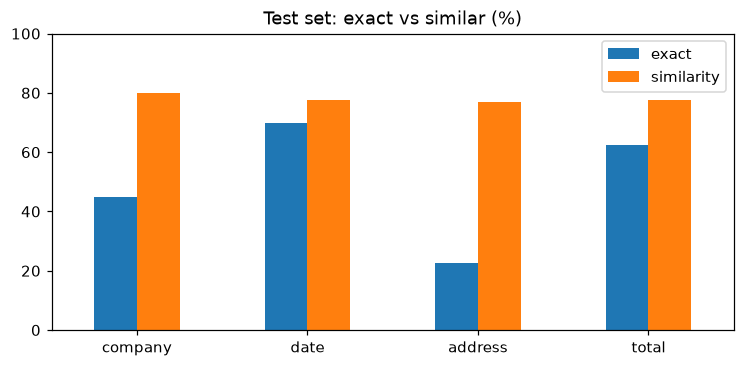

In [25]:
test_scores = field_summary.xs("test", axis=1, level="split")[["exact", "similarity"]] * 100
ax = test_scores.plot.bar(rot=0, figsize=(8, 3.5), title="Test set: exact vs similar (%)")
ax.set_xlabel(""); ax.set_ylim(0, 100); plt.show()

The gap between **exact** and **similar** is large, especially for address: many answers are *nearly* right but have one or two wrong characters.

### 3.2 Examples

In [26]:
test_fields = fields[fields.split == "test"]
for f in FIELDS:
    sub = test_fields[test_fields.field == f]
    print(f"===== {f}")
    for label, part in [("right", sub[sub.exact == 1].head(2)), ("wrong", sub[sub.exact == 0].head(3))]:
        for _, r in part.iterrows():
            print(f"  [{label}] truth: {r.truth}")
            print(f"          pred : {r.pred}")
    print()

===== company
  [right] truth: OJC MARKETING SDN BHD
          pred : OJC MARKETING SDN BHD
  [right] truth: OJC MARKETING SDN BHD
          pred : OJC MARKETING SDN BHD
  [wrong] truth: PERNIAGAAN ZHENG HUI
          pred : PERNIAGAAN ZHENG HU!
  [wrong] truth: CROSS CHANNEL NETWORK SDN. BHD.
          pred : CROSS CHANNEL NEiWORK SDN. BHD
  [wrong] truth: SWC ENTERPRISE SDN BHD
          pred : eee ENTERPRISE SDN BHD

===== date
  [right] truth: 15/01/2019
          pred : 15/01/2019
  [right] truth: 02/01/2019
          pred : 02/01/2019
  [wrong] truth: 09/02/2018
          pred : 09/02/2078
  [wrong] truth: 05/02/2018
          pred : 08/02/2018
  [wrong] truth: 08/01/2018
          pred : 06/01/2018

===== address
  [right] truth: NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, 81750 MASAI, JOHOR
          pred : NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, 81750 MASAI, JOHOR
  [right] truth: 47, JALAN MERANTI 1, SEK. 3, BANDAR UTAMA BATANG KALI, 44300 BATANG KALI, SELANGOR.
          pre

## 4. Error analysis: why are answers wrong?

Every wrong answer falls into one of three groups, and only one of them can be fixed by better rules:

1. **Answer not in receipt text (label).** The `entities` answer doesn't appear in the receipt's own `box` text. The answer key itself is inconsistent.
2. **OCR misread / missed it.** The answer is on the receipt, but not in the OCR text, so no rule could find it.
3. **Rule picked wrong text.** The answer *is* in the OCR text, but the rule chose something else. This is the only group better rules can fix.

The checks ignore spaces and punctuation. It's an approximation: a short answer like a total (`6.35` → `635`) can appear somewhere else in the text by chance.

In [27]:
gt_text = {(s, i): t for s, i, t in zip(df.split, df.id, df.text)}


def ocr_text(split, rid):
    return read_ocr(RESULTS / split / f"psm{PSM}", "auto", rid, MIN_WORDS)


def why_wrong(r):
    answer = squash(r["truth"])
    if answer not in squash(gt_text[(r["split"], r["id"])]):
        return "1 answer not in receipt text (label)"
    if answer not in squash(ocr_text(r["split"], r["id"])):
        return "2 OCR misread / missed it"
    return "3 rule picked wrong text"


misses = fields[fields.exact == 0].copy()
misses["reason"] = misses.apply(why_wrong, axis=1)
test_misses = misses[misses.split == "test"]
reasons = pd.crosstab(test_misses.field, test_misses.reason).reindex(FIELDS).fillna(0).astype(int)
reasons

reason,1 answer not in receipt text (label),2 OCR misread / missed it,3 rule picked wrong text
field,,,
company,6,136,49
date,1,86,18
address,15,165,89
total,0,57,73


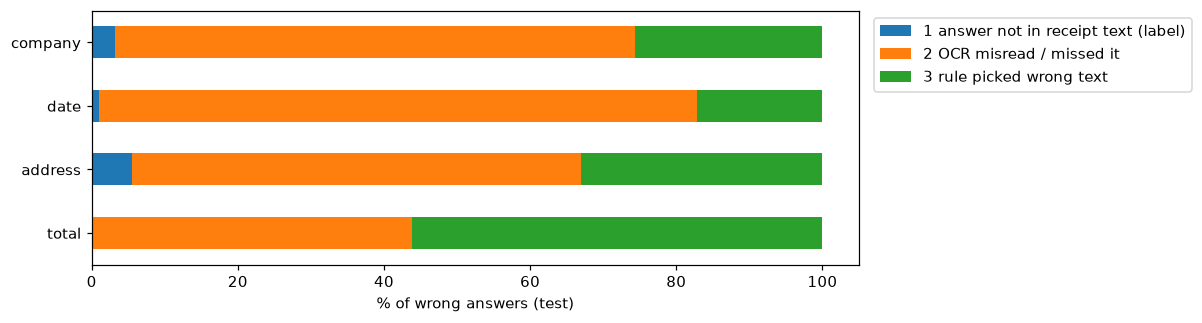

In [28]:
ax = reasons.div(reasons.sum(axis=1), axis=0).mul(100).plot.barh(stacked=True, figsize=(9, 3))
ax.set_xlabel("% of wrong answers (test)"); ax.set_ylabel("")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); ax.invert_yaxis(); plt.show()

**Result.** On the test set, most wrong answers come from OCR, not from the rules:

| Field | Answer-key error | OCR error | Rule error |
|---|---|---|---|
| company | 3% | 71% | 26% |
| date | 1% | 82% | 17% |
| address | 6% | 61% | 33% |
| total | 0% | 44% | **56%** |

Total is the only field where rule errors outnumber OCR errors, so it has the most room for better rules, for example preferring the amount on a "rounded total" line over the largest amount. Part of that share may be an artefact of the approximation: a short total like `635` can appear in the OCR text by chance.

### 4.1 Examples of answer-key errors
Some "wrong" answers are actually right, and the answer key is wrong:

- `X00016469670`: the receipt says **81750** MASAI; the answer key says **B1750**.
- `X51005337867`: OCR read **Old Town Kopitiam Sdn Bhd** (the real name); the answer key has **KOPITAM SND BHD** (two typos).
- `X51005361906`: answer key says **TED HENG**; the same shop is **TEO HENG** on its other receipts.

In [29]:
known = ["X00016469670", "X51005337867", "X51005361906"]
test_fields[test_fields.id.isin(known) & test_fields.field.isin(["company", "address"])][["id", "field", "truth", "pred", "exact"]]

,id,field,truth,pred,exact
0,X00016469670,company,OJC MARKETING SDN BHD,OJC MARKETING SDN BHD,1
2,X00016469670,address,"NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, B1750 MASAI, JOHOR","NO 2 &4, JALAN BAYU 4, BANDAR SERI ALAM, 81750 MASAI, JOHOR",0
52,X51005337867,company,OLD TOWN KOPITAM SND BHD,Old Town Kopitiam Sdn Bhd,0
54,X51005337867,address,SRI RAMPAI,Sri Rampai,1
60,X51005361906,company,TED HENG STATIONERY & BOOKS,TEO HENG sa RY,0
62,X51005361906,address,"NO. 53, JALAN BESAR, 45600 BATANG BERJUNTAI SELANGOR DARUL EHSAN","coors NO. 53, JALAN BESAR, CASH",0


## 5. Overfitting check: test vs. train

The extraction rules were improved by looking at **test** misses. That risks overfitting by hand: rules that fit these 347 receipts better without being better in general.

The check: run the same rules on the **626 train receipts**, which were never looked at while writing the rules. Similar scores mean the rules generalise.

In [30]:
over = (field_summary["exact"][["test", "train"]] * 100).round(1)
over["gap (train − test)"] = (over["train"] - over["test"]).round(1)
over

split,test,train,gap (train − test)
field,,,
company,45.0,41.1,-3.9
date,69.7,70.4,0.7
address,22.5,19.4,-3.1
total,62.5,62.4,-0.1


**Reading the result.** Date and total hold up on train (+0.7 and −0.1 points). Both depend on *formats* (`dd/mm/yy`, "largest amount on a TOTAL line"), which are the same on every receipt. Company and address drop 3.9 and 3.1 points. Their rules include specific words added after looking at test receipts (`PERNIAGAAN`, `SB`, skip rules), and some of those fixes mostly helped the receipts they were made for.

**Caveat.** The train receipts are unseen, but most of their **shops** are not: 73% of test receipts come from a shop that also appears in train (section 1.9). So this check measures generalisation to new receipts from mostly familiar shops. On completely new shops, company and address scores would likely be lower.

On the OCR side there was nothing to tune, and section 2.1 shows test and train scores are almost identical.

## 6. Conclusions and next steps

All results use Tesseract page mode `--psm 4`.

**Data**
- 973 receipts (626 train / 347 test) with an uppercase-only answer key. The two splits are very similar, and 73% of test receipts come from shops that also appear in train.
- The answer key is not perfect: about 5% of addresses and 2% of company names can't be found in the receipt's own text.

**OCR**
- Tesseract gets about **70% of words** exactly right (word F1: 70.6% test, 70.1% train, auto mode).
- Clean-up is **not** universally better: it improves 30% of receipts and worsens 35%. Its gains are concentrated in the palest receipts.
- Raw OCR returned no text for 17 receipts. Clean-up returns text for all of them, but sometimes mostly garbage.
- **Auto** mode (raw, with clean-up as a fallback) gives the lowest error rate: CER 24.4% test / 24.1% train.

**Field extraction (exact match, test)**
- Date **69.7%**, total **62.5%**, company **45.0%**, address **22.5%**.
- Similarity is much higher (77–80% for every field), so many misses are near misses with one or two misread characters.
- OCR errors cause most wrong answers: 61–82% for company, date and address. Total is the exception: 56% of its misses are rule errors, which makes it the best target for rule improvements.

**Generalisation**
- Date and total hold up on the unseen train receipts (+0.7 and −0.1 points). Company and address drop 3.9 and 3.1 points: a small, measured amount of overfitting from tuning rules on test.

**Next steps**
- Investigate the 6 dark-ink receipts where raw OCR fails (possibly dark backgrounds or borders).
- Choose clean-up by image quality (`ink`) instead of word count.
- Prefer a "rounded total" line for totals when a receipt has one.
- Try other Tesseract page modes (`--psm 6`, `--psm 3`).
- Improve the OCR itself: OCR errors cause most wrong answers, so better rules alone have a limited ceiling.
- Use an **LLM** to extract fields from the OCR text, especially company and address.
- Fine-tune **LayoutLM** on the train split. It uses each word's position on the receipt as well as the text. Because train and test share most shops, also test it on shops it has never seen.